# **Creating Summary**


Data-frames Created using LO4 Correlation

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Visitor data
data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueDailyVisitors.csv', index_col=0)
data.index = pd.to_datetime(data.index)
print(data.head())

# Venue characteristic datasets
age_data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueAge.csv', index_col=0)
distance_data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueDistance.csv', index_col=0)
duration_data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueDuration.csv', index_col=0)
gender_data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueGender.csv', index_col=0)
spend_data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueSpend.csv', index_col=0)

# Create summary dataframe
summary_data = pd.DataFrame(index=data.columns)

summary_data['Visitors'] = data.sum().values
summary_data['AverageAge'] = age_data.values
summary_data['DistanceTravelled'] = distance_data.values
summary_data['VisitDuration'] = duration_data.values
summary_data['FemalePercentage'] = gender_data.values
summary_data['AverageSpend'] = spend_data.values

print(summary_data.head())
print(summary_data.describe())

            SRZ  TLP  PLY  LXE  ULW  SXK  PFN  OFF  MXL  LLJ  ...  UOR  VAU  \
Date                                                          ...             
2023-01-01  109   87  296   69   77   90  525  239    0    0  ...  662  546   
2023-01-02   69   74  296   55   63   89  496  265    0    0  ...  481  523   
2023-01-03   84   99  211   56   66   62  394  166    0    0  ...  345  417   
2023-01-04  108   53  169   81   83   87  346  121    0    0  ...  502  351   
2023-01-05   80   92  222   50   66  101  341  177    0    0  ...  461  366   

            URJ  TDE  VDM  RLH  XDV  MFY  KFO  VXB  
Date                                                
2023-01-01   69  103   71   50   85  161    0   90  
2023-01-02   73   71   80   57   92  196    0  128  
2023-01-03   70  100   75   60   93  101    0   71  
2023-01-04   76   85   57   69   87   89    0   85  
2023-01-05   74   84   59   58   77   93    0   80  

[5 rows x 35 columns]
     Visitors  AverageAge  DistanceTravelled  VisitD

# To Segment Data trying to find the capping points for High medium and Low

In [ ]:
# Sum visitors for each venue and sort descending
visitor_totals = data.sum().sort_values(ascending=False)

print(visitor_totals)

UOR    186766
VUJ    174575
VAU    162345
PFN    156935
PLY     87174
QXC     86985
QRS     84702
OFF     72656
NLQ     66117
PRK     56982
MFY     54947
OXV     52483
VXB     33834
TDE     32141
SXK     31946
SRZ     31405
WJG     30113
YRY     30024
TLP     29177
XXJ     27589
URJ     27195
UXT     25198
VDM     24964
ULW     24439
RDX     23096
RLH     22166
WRQ     21904
XDV     15988
MXL     13944
LRT     13366
KLZ     10996
LXE     10963
NRB      8894
LLJ      4618
KFO      3538
dtype: int64


# **Visualisation 1**

LO2 Proportion - Barchart grouped Sorted and coloured

high_volume = ['UOR', 'VUJ', 'VAU', 'PFN']
medium_volume = ['PLY', 'QXC', 'QRS', 'OFF', 'NLQ', 'PRK', 'MFY', 'OXV']
low_volume = ['VXB', 'TDE', 'SXK', 'SRZ', 'WJG', 'YRY', 'TLP', 'XXJ', 'URJ', 'UXT', 'VDM', 'ULW', 'RDX', 'RLH', 'WRQ', 'XDV', 'MXL', 'LRT', 'KLZ', 'LXE']
very_low_volume = ['NRB', 'LLJ', 'KFO']


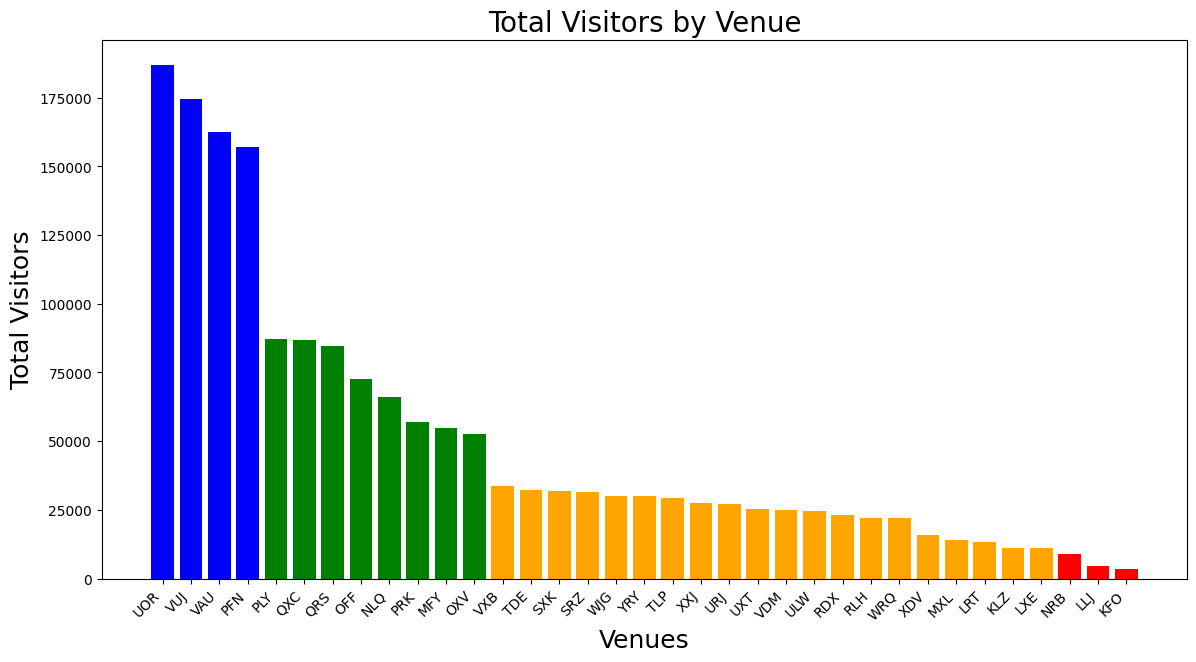

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Visitor data
data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueDailyVisitors.csv', index_col=0)
data.index = pd.to_datetime(data.index)
data = data.reindex(data.sum().sort_values(ascending=False).index, axis=1)
segment_limits = {
    0: 'Very Low',
    10_000: 'Low',
    40_000: 'Medium',
    100_000: 'High',
}
limits = list(segment_limits.keys())
segments = {}
for i in range(len(limits)):
    if i < len(limits) - 1:
        included = (limits[i] <= data.sum()) & (data.sum() < limits[i + 1])
    else:
        included = (limits[i] <= data.sum())
    segment_name = segment_limits[limits[i]]
    segment_columns = data.columns[included]
    segments[segment_name] = list(segment_columns)

for segment_name in reversed(segments):
    print(f'{segment_name.lower().replace(" ", "_")}_volume = {segments[segment_name]}')

segment_colours = {
    'Very Low': 'red',
    'Low': 'orange',
    'Medium': 'green',
    'High': 'blue',
}
colours = []
for name in data.columns:
    for segment_name in segments:
        if name in segments[segment_name]:
            colour = segment_colours[segment_name]
            colours.append(colour)
            break

plt.figure(figsize=(14, 7))
x_pos = np.arange(len(data.columns))
plt.bar(x_pos, data.sum(), align='center', color=colours)
plt.xticks(x_pos, data.columns, rotation=45, ha='right')
plt.xlabel('Venues', fontsize=18)
plt.ylabel('Total Visitors', fontsize=18)
plt.title('Total Visitors by Venue', fontsize=20)
plt.show()

# **Visualisation 2**

Heatmap Summary Correlation from LO4 Correlation

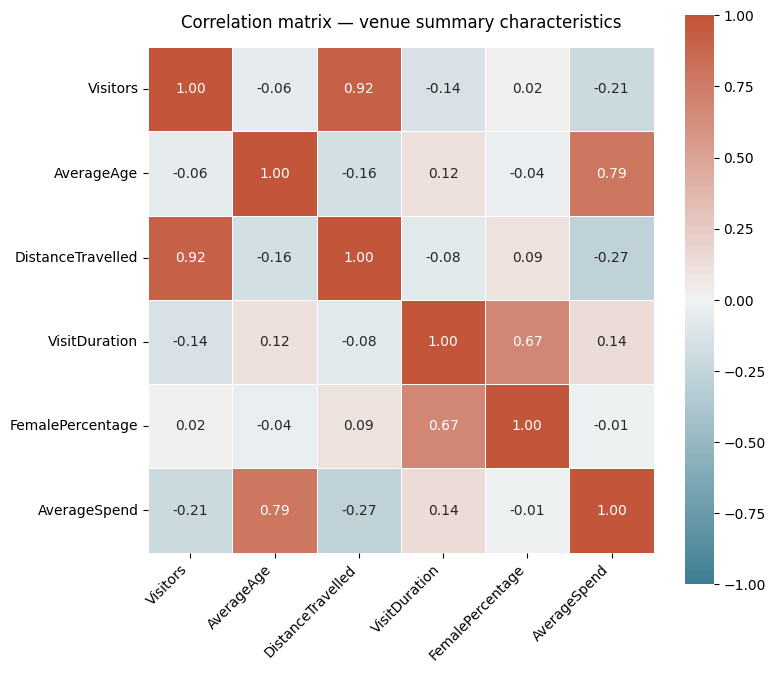

In [ ]:
import seaborn as sns

# Correlation heatmap
plt.figure(figsize=(8, 7))
corr = summary_data.corr()

ax = sns.heatmap(
    corr,
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(220, 20, n=200),
    square=True,
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
ax.set_title('Correlation matrix — venue summary characteristics', pad=14)

plt.tight_layout()
plt.show()

# **Visualisation 3**

**Line Plot of Total Visitors and Average Spend per Venue from LO3 Time**

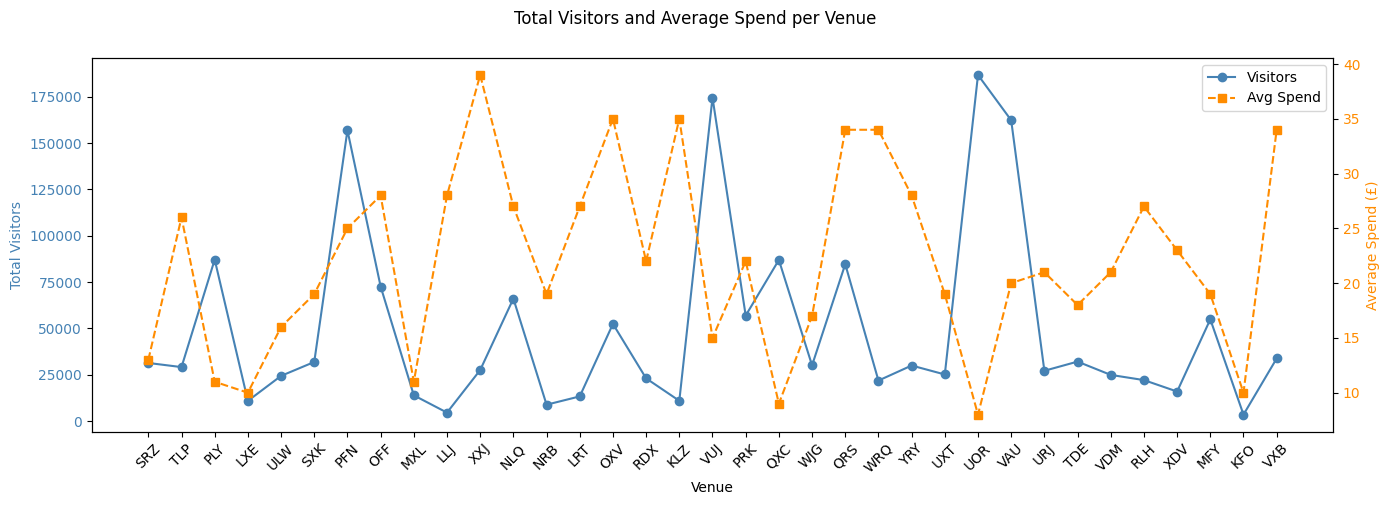

In [ ]:
# Line plot of Visitors and AverageSpend per venue
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(summary_data.index, summary_data['Visitors'], color='steelblue', marker='o', label='Visitors')
ax1.set_xlabel('Venue')
ax1.set_ylabel('Total Visitors', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(summary_data.index, summary_data['AverageSpend'], color='darkorange', marker='s', linestyle='--', label='Avg Spend')
ax2.set_ylabel('Average Spend (£)', color='darkorange')
ax2.tick_params(axis='y', labelcolor='darkorange')

fig.suptitle('Total Visitors and Average Spend per Venue', position=(0.5, 1.0))
fig.legend(loc='upper right', bbox_to_anchor=(1, 1), bbox_transform=ax1.transAxes)

plt.tight_layout()
plt.show()

# Sorting Venues by Average Spend to Identify the Top Five

In [ ]:
# Sort by highest average spend  top 5
summary_sorted = summary_data.sort_values('AverageSpend', ascending=False).head(5)

print("Top 5 venues by average spend:")
print(summary_sorted[['AverageSpend', 'Visitors']])

Top 5 venues by average spend:
     AverageSpend  Visitors
XXJ            39     27589
OXV            35     52483
KLZ            35     10996
QRS            34     84702
VXB            34     33834


# **Visualisation 4**

**Radar plot Top Venues by Average spend from LO6 Dimension**

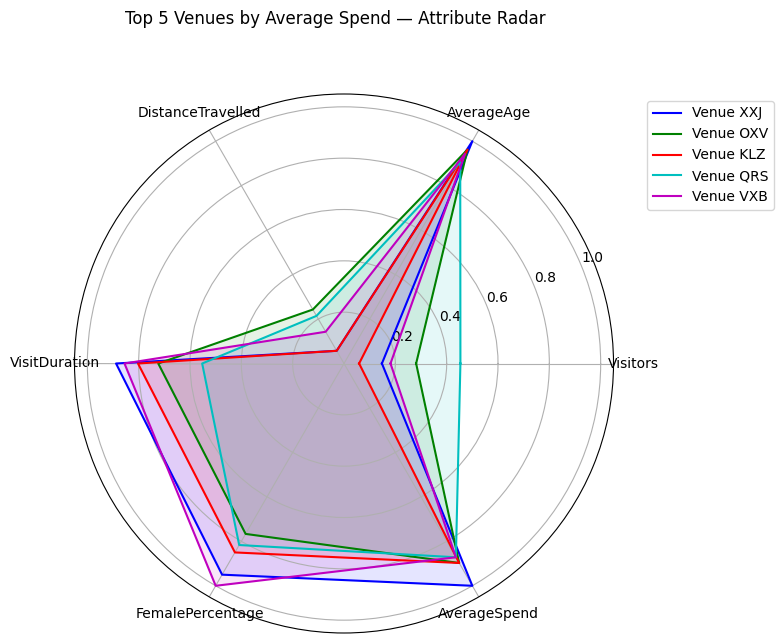

In [ ]:
# Normalise
normalised_data = summary_data / summary_data.max()

# Top 5 venues by average spend
selected = ['XXJ', 'OXV', 'KLZ', 'QRS', 'VXB']

n_attributes = len(normalised_data.columns)
angles = [n / float(n_attributes) * 2 * np.pi for n in range(n_attributes + 1)]
colours = ['b', 'g', 'r', 'c', 'm']
c = 0

plt.figure(figsize=(7, 7))
sub = plt.subplot(1, 1, 1, polar=True)

for name in selected:
    values = normalised_data.loc[[name]].values.flatten().tolist()
    values += values[:1]
    sub.plot(angles, values, colours[c % len(colours)], label='Venue ' + name)
    sub.fill(angles, values, colours[c % len(colours)], alpha=0.1)
    sub.set_ylim(ymax=1.05)
    sub.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    sub.set_xticks(angles[0:-1])
    sub.set_xticklabels(normalised_data.columns)
    c += 1

plt.legend(loc='upper left', bbox_to_anchor=(1.05, 1.0))
plt.suptitle('Top 5 Venues by Average Spend — Attribute Radar', position=(0.5, 1.0))
plt.show()

# **Visualisation 5**

**Seasonal Behaviour**

Box Plot of Visitor Distribution by day of week from LO5 Distribution

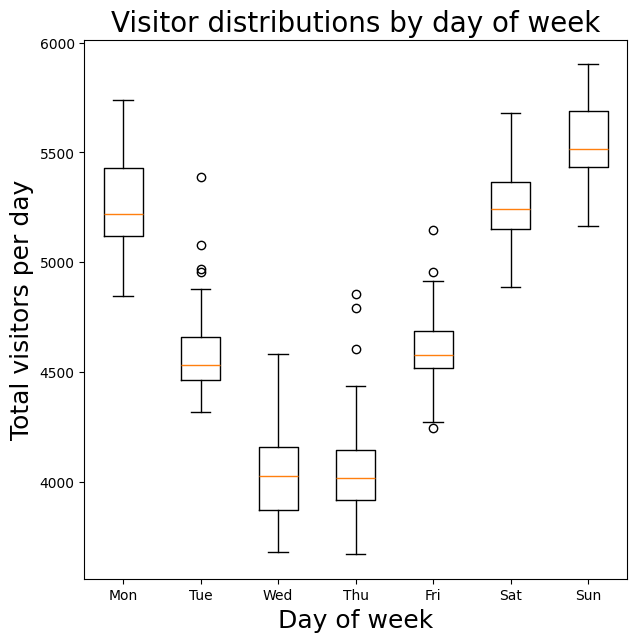

In [ ]:
# Sum across all venues per day, then group by day of week
daily_total = data.sum(axis=1)
daily_df = pd.DataFrame({'TotalVisitors': daily_total})
daily_df['DayOfWeek'] = daily_df.index.day_name()

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

grouped = [daily_df[daily_df['DayOfWeek'] == d]['TotalVisitors'].values for d in dow_order]
short_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

plt.figure(figsize=(7, 7))
plt.boxplot(grouped, tick_labels=short_labels)
plt.xlabel('Day of week', fontsize=18)
plt.ylabel('Total visitors per day', fontsize=18)
plt.title('Visitor distributions by day of week', fontsize=20)
plt.show()

# **Visualisation 6**

 **Monthly Visitor Distribution by Venue — High & Medium Volume (Subplot)**

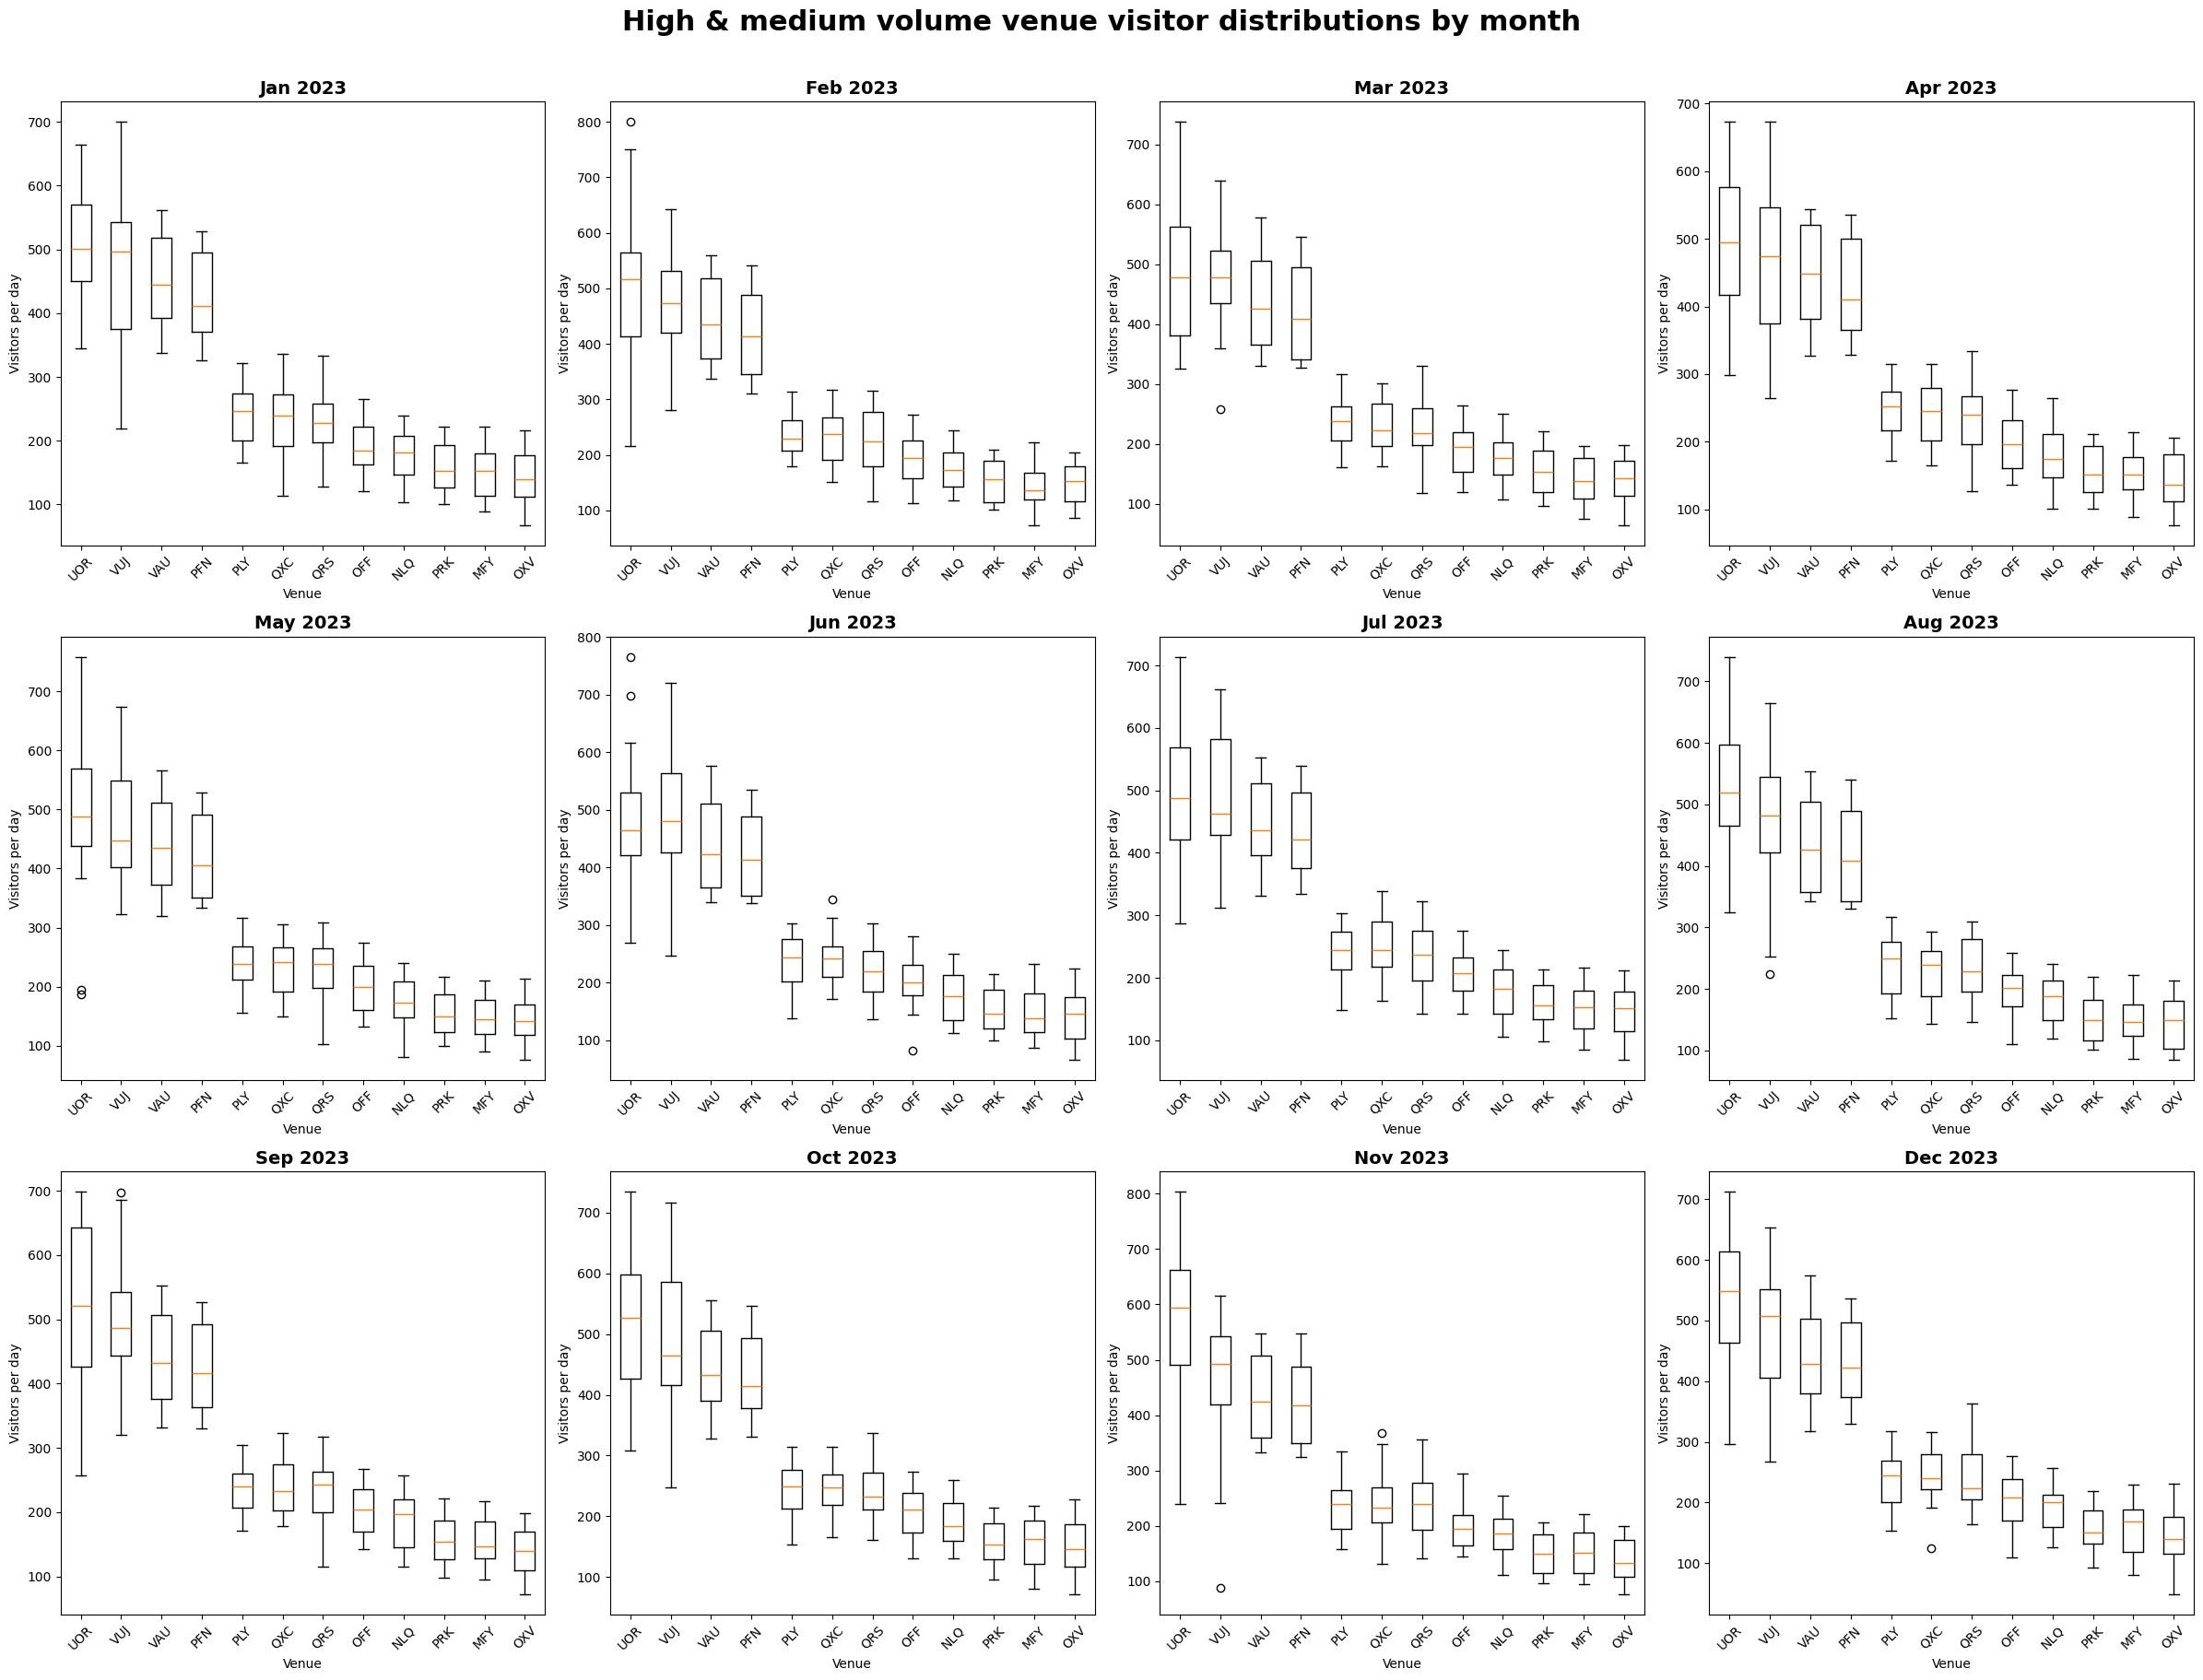

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv('https://tinyurl.com/ChrisCoDV/001518490/VenueDailyVisitors.csv', index_col=0)
data.index = pd.to_datetime(data.index)

selected = ['UOR', 'VUJ', 'VAU', 'PFN', 'PLY', 'QXC', 'QRS', 'OFF', 'NLQ', 'PRK', 'MFY', 'OXV']

months = list(data[selected].resample('ME'))

fig, axes = plt.subplots(3, 4, figsize=(24, 18))
axes = axes.flatten()

for i, (month, month_data) in enumerate(months):
    axes[i].boxplot(month_data, tick_labels=selected)
    axes[i].set_title(month.strftime('%b %Y'), fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Venue', fontsize=10)
    axes[i].set_ylabel('Visitors per day', fontsize=10)
    axes[i].tick_params(axis='x', rotation=45)

fig.suptitle('High & medium volume venue visitor distributions by month',
             fontsize=22, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# **Pairplot — Venue Characteristics (Visitors, Age, Distance, Duration, Gender & Spend)**

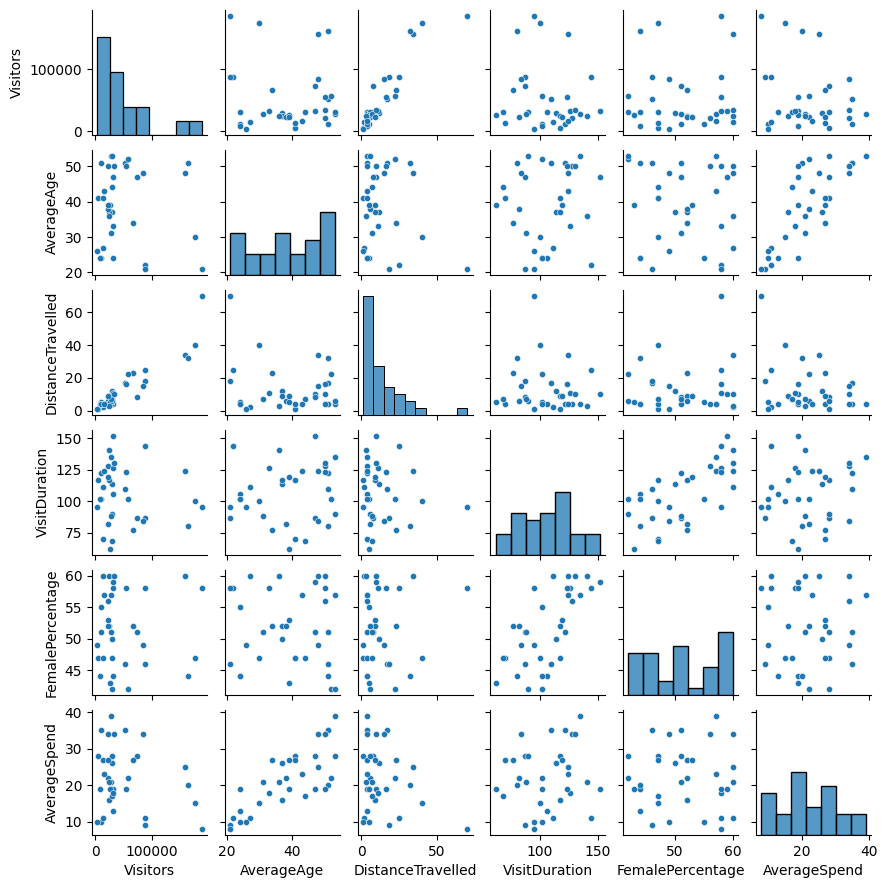

In [ ]:
sns.pairplot(summary_data, height=1.5, plot_kws={'s': 20})
plt.show()